# Blade Envelopes: the Active Subspace of Profile Loss for the VKI LS89 Turbine Cascade

__Chun Yui Wong__, Department of Engineering, University of Cambridge, U.K.

__Pranay Seshadri__, Department of Mathematics, Imperial College London, U.K., and Data-Centric Engineering, The Alan Turing Institute, U.K.

__Ashley Scillitoe__, Data-Centric Engineering, The Alan Turing Institute, U.K.

__Andrew B. Duncan__, Department of Mathematics, Imperial College London, U.K., and Data-Centric Engineering, The Alan Turing Institute, U.K.

__Geoffrey Parks__, Department of Engineering, University of Cambridge, U.K.

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook analyzes the SU2 runs of Wong et al. [[1]](https://doi.org/10.1115/1.4053239) ("Blade Envelopes Part I: Concept and Methodology"), which the authors published in the [equadratures/data-sets](https://github.com/equadratures/data-sets) repository. Affiliations and page, table and figure numbers are from the arXiv preprint (arXiv:2011.11636v5, the accepted manuscript TURBO-20-1443); the published version is J. Turbomach. 144(6), 2022. It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about half a minute.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import convert_data as cd

SEED = 2022                       # the only seed in this notebook (bootstrap replicates)
t_start = time.perf_counter()
labels = [f'$x_{{{j}}}$' for j in range(1, 21)]

### Summary

Wong et al. [[1]](https://doi.org/10.1115/1.4053239) perturb the VKI LS89 transonic turbine blade with 20 free-form-deformation (FFD) design variables, run a 2-D RANS solve with SU2 for 1000 random designs, and find that the stagnation pressure loss coefficient $Y_p$ has a one-dimensional active subspace, whose 19-dimensional complement they sample to draw manufacturing tolerances ("blade envelopes"). We estimate the active subspace from their published runs, without new CFD, using a global least-squares quadratic (QPHD) on the 997 runs with a finite loss and local linear gradients as a cross-check. Both estimators find one dominant direction, with the eigenvalue magnitudes, the gap and the sufficient summary plot of the paper's Fig. 9; the direction is a coordinated thickening and thinning of the blade carried mostly by the FFD variables $x_5$–$x_7$ and $x_{11}$–$x_{14}$.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. When only values of $f$ are available, $\nabla f$ is replaced by the gradient of a fitted model, here a global quadratic or local linear fits, and the estimate is assessed with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Geometry.** The VKI LS89 linear cascade (Arts and Lambert de Rouvroit [[2]](https://doi.org/10.1115/1.2927978)) is a highly loaded transonic nozzle guide vane with a chord of about 67 mm and a stagger angle of 55° ([[1]](https://doi.org/10.1115/1.4053239) p. 4). The blade is deformed by $d = 20$ FFD design variables, "scaled to lie within the range −1 to 1, such that each design vector $\mathbf x\in[-1,1]^{d}$"; the FFD nodes move only perpendicular to the inflow (Sec. 2.1, p. 4, Fig. 3). The paper does not give the physical displacement behind the scaling. In the authors' run scripts ([ncywong/VKI_CFD](https://github.com/ncywong/VKI_CFD), `makedirs.py`), variable $j$ (1-based) is the displacement in $y$ of the FFD control point $(i, k) = (\lfloor (j-1)/10\rfloor, (j-1) \bmod 10)$ of a box of degree (1, 9), in mesh units, equal to $0.01\,x_j$ (default `bound = 0.01`); we have not verified that the published runs used that default. The paper says the deformations "grossly exaggerate" real manufacturing deviations.

**Flow solver.** SU2 [[3]](https://doi.org/10.2514/1.J053813) deforms the mesh and solves the steady 2-D Reynolds-averaged Navier–Stokes equations with the Spalart–Allmaras model, fully turbulent, with a stagnation-pressure inlet, a static-pressure outlet, periodic pitchwise boundaries and a freestream turbulent viscosity ratio of 100 (Sec. 2.2, p. 4). The flow conditions are those of Table 1 (p. 5): $p_{01} = 1.1\times10^6$ N m$^{-2}$, $T_{01} = 592.295$ K, $\rho = 1.2866$ kg m$^{-3}$, $Re = 6.0\times10^5$, $p_2 = 5.23\times10^5$ N m$^{-2}$, $\gamma = 1.4$.

**Quantity of interest.** The stagnation pressure loss coefficient (Eq. 2, p. 5), with $p_{02}$ the circumferentially mass-averaged exit stagnation pressure:

$$
Y_p = \frac{p_{01} - p_{02}}{p_{02} - p_2}.
$$

The preprint prints the numerator as $p_{02} - p_{01}$, which would make $Y_p$ negative; the authors' post-processing (`get_loss_from_file` in `util_funcs.py` of VKI_CFD) computes $p_{01} - p_{02}$, as above, and every finite value in the data is positive. The paper also records the exit mass flow function and the isentropic Mach number distribution; only $Y_p$ is in the published data set.

**Inputs and design.** The 20 inputs are independent and uniform on $[-1, 1]$ (the hypercube with density $2^{-d}$, Eq. 7). The paper's design is 1000 uniform Monte Carlo samples (Sec. 2.3, p. 5), split 800/200 for training and testing a polynomial; no seed is given. The table below is built from `convert_data.py`, which names the inputs and their bounds.

In [2]:
print(f"{'input':6s} {'lower':>6s} {'upper':>6s} {'nominal':>8s}  FFD control point (i, k) moved in y, per VKI_CFD makedirs.py")
for j, n in enumerate(cd.NAMES):
    print(f'{n:6s} {cd.LOWER[j]:6.0f} {cd.UPPER[j]:6.0f} {0:8.0f}  ({j // 10}, {j % 10}); displacement 0.01 x{j + 1} in mesh units (unverified)')

input   lower  upper  nominal  FFD control point (i, k) moved in y, per VKI_CFD makedirs.py
x1         -1      1        0  (0, 0); displacement 0.01 x1 in mesh units (unverified)
x2         -1      1        0  (0, 1); displacement 0.01 x2 in mesh units (unverified)
x3         -1      1        0  (0, 2); displacement 0.01 x3 in mesh units (unverified)
x4         -1      1        0  (0, 3); displacement 0.01 x4 in mesh units (unverified)
x5         -1      1        0  (0, 4); displacement 0.01 x5 in mesh units (unverified)
x6         -1      1        0  (0, 5); displacement 0.01 x6 in mesh units (unverified)
x7         -1      1        0  (0, 6); displacement 0.01 x7 in mesh units (unverified)
x8         -1      1        0  (0, 7); displacement 0.01 x8 in mesh units (unverified)
x9         -1      1        0  (0, 8); displacement 0.01 x9 in mesh units (unverified)
x10        -1      1        0  (0, 9); displacement 0.01 x10 in mesh units (unverified)
x11        -1      1        0  (1, 0)

### Load data

`convert_data.py` copied four arrays of the authors' `blade_envelopes.npz` losslessly into CSV files (see `DATA.md`): the 1000 × 20 design variables, the 1000 loss values, and the $x$ and $y$ coordinates of 240 points on the blade surface (the $x$ coordinates are the same for every design). Three loss values are `inf`: in the authors' post-processing, `inf` is the value returned when a run "diverged" (its final log10 density residual is above −8, or it wrote no flow file). **Rule:** we drop the rows whose loss is not finite. The rows stay in the file.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')            # (1000, 20) scaled FFD variables
f_all = np.loadtxt('outputs.csv', delimiter=',')       # (1000,) Yp, inf where a run diverged
xb = np.loadtxt('blade_x.csv', delimiter=',')          # (240,) blade-surface x, m
Yb = np.loadtxt('blade_y.csv', delimiter=',')          # (1000, 240) blade-surface y, m
ok = np.isfinite(f_all)
Xf, f = X[ok], f_all[ok]
print(f'inputs {X.shape}, outputs {f_all.shape}, blade x {xb.shape}, blade y {Yb.shape}')
print(f'non-finite loss in rows {np.flatnonzero(~ok).tolist()} (0-based); {ok.sum()} runs kept')
print(f'X in [{X.min():.4f}, {X.max():.4f}]; Yp in [{f.min():.4f}, {f.max():.4f}], '
      f'mean {f.mean():.4f}, standard deviation {f.std(ddof=1):.4f}')

inputs (1000, 20), outputs (1000,), blade x (240,), blade y (1000, 240)
non-finite loss in rows [74, 224, 474] (0-based); 997 runs kept
X in [-1.0000, 0.9999]; Yp in [0.0297, 0.1055], mean 0.0473, standard deviation 0.0097


#### The blade shapes

The blade coordinates let us see what the design variables do. If the FFD map is linear, each design's surface is $\mathbf s(\mathbf x) = \mathbf s_0 + \mathbf B^T\mathbf x$, with $\mathbf s_0$ the undeformed LS89 ($\mathbf x = 0$) and row $j$ of $\mathbf B$ the surface displacement per unit $x_j$. We fit $\mathbf s_0$ and $\mathbf B$ by least squares to the 1000 stored shapes and check the residual.

linear FFD map: largest residual 6.2e-09 m over 1000 x 240 points (displacements are up to 8.0 mm)
largest surface displacement per unit x_j (mm):
x1 0.63, x2 1.10, x3 1.46, x4 1.74, x5 1.96, x6 2.16, x7 2.37, x8 2.67, x9 3.31, x10 0.00, x11 4.42, x12 3.51, x13 2.35, x14 1.76, x15 1.43, x16 1.24, x17 1.14, x18 1.12, x19 1.24, x20 0.00


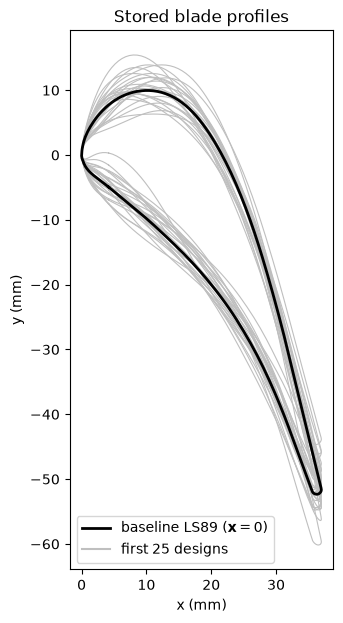

In [4]:
A = np.column_stack([np.ones(len(X)), X])
coef, *_ = np.linalg.lstsq(A, Yb, rcond=None)
s0, Bmap = coef[0], coef[1:]                  # (240,) baseline y, (20, 240) displacement per unit x_j, m
resid = np.abs(Yb - A @ coef).max()
dmax = np.abs(Bmap).max(axis=1) * 1e3         # mm
print(f'linear FFD map: largest residual {resid:.1e} m over 1000 x 240 points '
      f'(displacements are up to {np.abs(Yb - s0).max() * 1e3:.1f} mm)')
print('largest surface displacement per unit x_j (mm):')
print(', '.join(f'x{j + 1} {d:.2f}' for j, d in enumerate(dmax)))

fig, ax = plt.subplots(figsize=(6, 7))
for i in range(25):
    ax.plot(np.r_[xb, xb[0]] * 1e3, np.r_[Yb[i], Yb[i, 0]] * 1e3, color='0.75', lw=0.8)
ax.plot(np.r_[xb, xb[0]] * 1e3, np.r_[s0, s0[0]] * 1e3, 'k', lw=2, label='baseline LS89 ($\\mathbf{x} = 0$)')
ax.plot([], [], color='0.75', label='first 25 designs')
ax.set_aspect('equal')
ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')
ax.legend(loc='lower left')
ax.set_title('Stored blade profiles')
plt.close(fig)
fig

The fit is exact to rounding: the largest residual is $6.2\times10^{-9}$ m, while the designs move the surface by up to 8.0 mm. So the stored surfaces are a linear function of $\mathbf x$, and each design variable has a single displacement shape; the largest displacement per unit $x_j$ ranges from 0.63 mm ($x_1$) to 4.42 mm ($x_{11}$). Two variables, $x_{10}$ and $x_{20}$, move no stored surface point (0.00 mm); in the VKI_CFD numbering they are the last control point of each row, $(0, 9)$ and $(1, 9)$. The paper does not say how the stored coordinates were produced (read from the deformed SU2 meshes, or recomputed from the FFD), so we cannot tell from the data whether the CFD surfaces moved with these two variables; we return to them below.

### Estimate the subspace

The published data have values of $Y_p$ only; SU2's adjoint was not used. The paper estimates gradients from a sparse total-order cubic (1771 terms) fitted by compressed sensing with equadratures, which needs no more runs than terms (Sec. 3.2, pp. 6–8). With 997 runs and $m = 20$, a full least-squares quadratic (231 terms, $997 \ge 2 \times 231$) is well determined, so we use the library's **global quadratic estimator** (`estimator="qphd"`): it fits $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ in the normalized inputs and returns $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ with $\boldsymbol\Sigma = \tfrac13\mathbf I$, which is exactly $\mathbb E[\nabla q\,\nabla q^T]$ for the uniform density on the cube: the active subspace of the fitted quadratic, as in Seshadri et al. (2018), cited as [1] in the paper. The library issues a `ValidityWarning` for this estimator on a uniform space, because Li's interpretation of $\mathbf g$ and $\mathbf H$ as $\mathbb E[\nabla f]$ and $\mathbb E[\nabla^2 f]$ needs Gaussian inputs; the matrix is still the active subspace of the quadratic, so we record the warning and go on. The inputs are already the paper's normalized variables, so `ac.Uniform(-1, 1)` leaves them unchanged and the eigenvalues are directly comparable with Fig. 9(a).

We use 500 bootstrap replicates with seed `SEED`, keep the bootstrap replicates of the first two eigenvectors, and let the library's eigenvalue-gap rule choose $n$. Eigenvector signs are arbitrary; we orient $\mathbf w_1$ so that $Y_p$ decreases along it, as in the paper's Fig. 9(b).

In [5]:
space = ac.Uniform(cd.LOWER, cd.UPPER, names=list(cd.NAMES))
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    sub = ac.active_subspace(space=space, X=Xf, f=f, estimator='qphd', nboot=500,
                             bootstrap_vectors=2, rng=SEED)
for w in caught:
    print(f'{type(w.message).__name__}: {w.message}')
sub = ac.orient(sub, by='covariance', X=Xf, f=-f, columns=2)     # Yp decreases along w1
lam, w1 = sub.eigenvalues, sub.W[:, 0]
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
print(f'QPHD with {sub.nboot} bootstrap replicates: {time.perf_counter() - t0:.1f} s')
print('eigenvalues:', np.array2string(lam, precision=2))
print(f'n = {sub.n} (eigenvalue-gap rule picks {k_hat}); lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, '
      f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}')

QPHD with 500 bootstrap replicates: 15.8 s
eigenvalues: [3.17e-04 1.24e-05 5.24e-06 2.63e-06 1.30e-06 1.04e-06 9.44e-07 7.96e-07
 5.77e-07 4.81e-07 3.54e-07 3.08e-07 2.38e-07 1.61e-07 1.29e-07 9.25e-08
 6.92e-08 5.81e-08 2.49e-08 1.60e-08]
n = 1 (eigenvalue-gap rule picks 1); lambda_1/lambda_2 = 25.6, lambda_2/lambda_3 = 2.36


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band. The black crosses are the first three eigenvalues of the paper's Fig. 9(a), read from the figure (log scale, so to about 10 %).

95 % bootstrap intervals: lambda_1 [2.84e-04, 3.47e-04]; lambda_2 [9.09e-06, 2.03e-05]; lambda_3 [3.85e-06, 9.88e-06]
eigenvalues 3-20 span 1.6e-08 to 5.2e-06


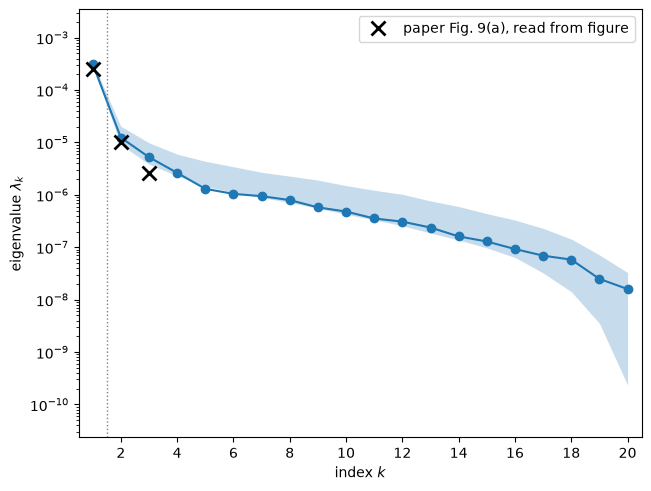

In [6]:
paper_lam = np.array([2.5e-4, 1.0e-5, 2.6e-6])        # read from Fig. 9(a) of [1]
fig, ax = ac.plotting.plot_eigenvalues(sub, interval='percentile')
ax.plot([1, 2, 3], paper_lam, 'kx', markersize=10, mew=2, label='paper Fig. 9(a), read from figure')
ax.legend()
plt.close(fig)
band = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
print('95 % bootstrap intervals: ' + '; '.join(
    f'lambda_{k + 1} [{band[0, k]:.2e}, {band[1, k]:.2e}]' for k in range(3)))
print(f'eigenvalues 3-20 span {lam[19]:.1e} to {lam[2]:.1e}')
fig

The eigenvalue-gap rule picks $n = 1$: $\lambda_1 = 3.17\times10^{-4}$ and $\lambda_2 = 1.24\times10^{-5}$, a ratio of 25.6, and the next ratio, $\lambda_2/\lambda_3$, is only 2.36. The 95 % bootstrap intervals of $\lambda_1$, $[2.84, 3.47]\times10^{-4}$, and $\lambda_2$, $[0.909, 2.03]\times10^{-5}$, are more than an order of magnitude apart. The paper's first two eigenvalues, read from Fig. 9(a) as about $2.5\times10^{-4}$ and $1.0\times10^{-5}$, are close: the paper's $\lambda_2$ lies inside our band, and its $\lambda_1$ lies about 20 % below our estimate, below our band. The tails differ: the paper's eigenvalues 4–20 decay slowly, from about $2\times10^{-6}$ to $3\times10^{-7}$, while ours fall from $2.63\times10^{-6}$ to $1.60\times10^{-8}$. The small eigenvalues of both estimates are mostly approximation error of the fitted polynomial (a 231-term quadratic here, a 1771-term sparse cubic in the paper), not structure of $Y_p$.

bootstrap mean subspace distance, k = 1..6: [0.058 0.344 0.492 0.702 0.884 0.905]


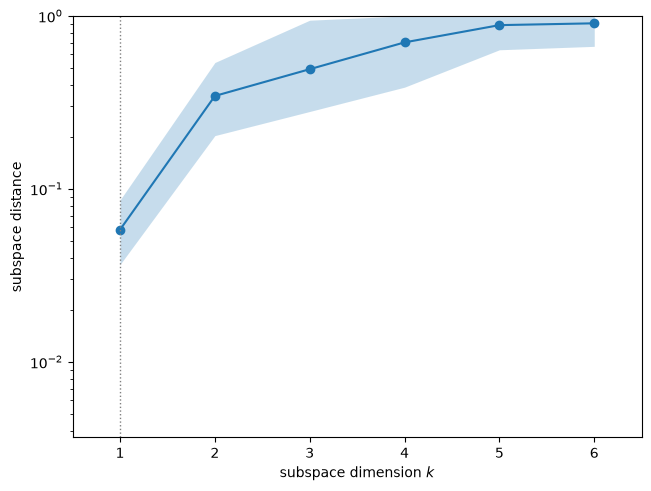

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub, interval='percentile', k_max=6)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..6:',
      np.array2string(sub.bootstrap_distances.mean(axis=0)[:6], precision=3))
fig

The bootstrap mean subspace distance is 0.058 for $k = 1$ and 0.344 or more for $k \ge 2$: 997 runs determine the first direction well and the second one poorly.

w1: x13 +0.543, x12 +0.426, x11 -0.408, x6 -0.316, x5 -0.258, x7 -0.254, x14 +0.252, x2 +0.155 ...
share of |w1|^2 in x5-x7 and x11-x14: 0.938
components whose 95 % bootstrap interval contains 0: x9 [-0.019, +0.047], x10 [-0.015, +0.041], x19 [-0.027, +0.021], x20 [-0.035, +0.009]


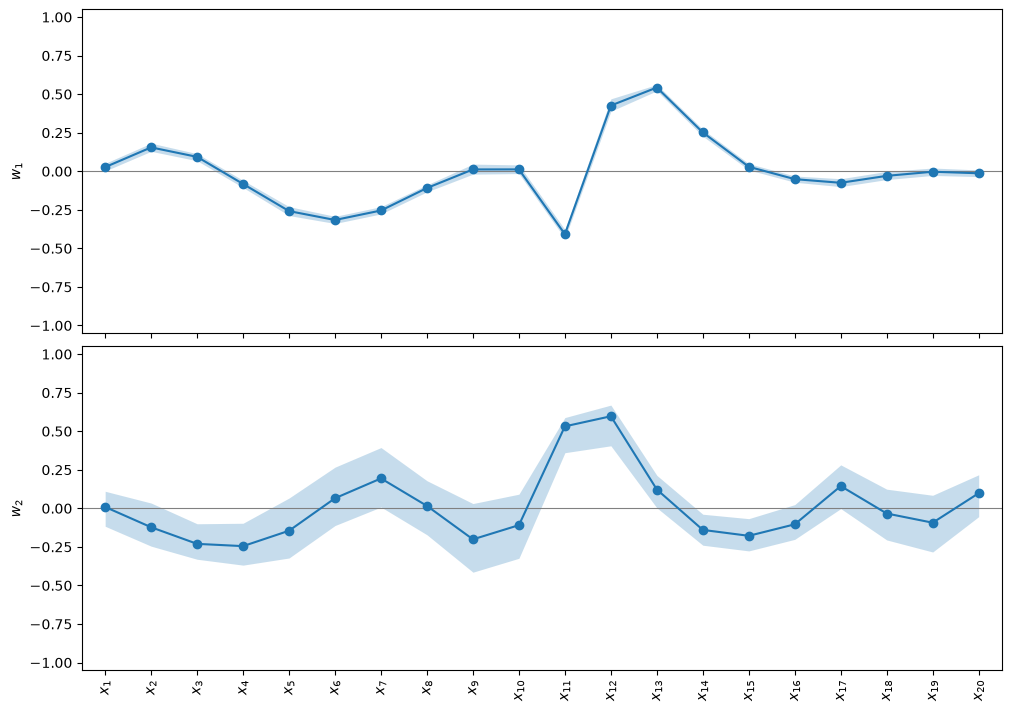

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, interval='percentile',
                                          figsize=(10, 7))
plt.close(fig)
vband = ac.bootstrap_interval(sub.bootstrap_eigenvectors[:, :, 0])
order = np.argsort(-np.abs(w1))
print('w1:', ', '.join(f'x{j + 1} {w1[j]:+.3f}' for j in order[:8]), '...')
print(f'share of |w1|^2 in x5-x7 and x11-x14: {np.sum(w1[[4, 5, 6, 10, 11, 12, 13]]**2):.3f}')
print('components whose 95 % bootstrap interval contains 0:',
      ', '.join(f'x{j + 1} [{vband[0, j]:+.3f}, {vband[1, j]:+.3f}]'
                for j in range(20) if vband[0, j] <= 0 <= vband[1, j]))
fig

Seven inputs dominate $\mathbf w_1$: $x_{13}$ (+0.543), $x_{12}$ (+0.426), $x_{11}$ (−0.408), $x_6$ (−0.316), $x_5$ (−0.258), $x_7$ (−0.254) and $x_{14}$ (+0.252), which together carry 0.938 of $\lVert\mathbf w_1\rVert^2$. In the VKI_CFD numbering these are control points 4–6 of the first row and 0–3 of the second. The bootstrap band of $\mathbf w_1$ is narrow, and the intervals of four components contain 0: $x_9$, $x_{10}$, $x_{19}$ and $x_{20}$. The second eigenvector has wide bands, as the subspace distances predict. The paper does not plot or tabulate its eigenvectors.

#### The active direction as a blade shape

Since the FFD map is linear, moving the design by $t\,\mathbf w_1$ moves the surface by $t\,\mathbf B^T\mathbf w_1$. The figure draws the baseline blade and the blades at $\mathbf x = \pm 1.5\,\mathbf w_1$ (the active variable is $\pm 1.5$, within the range of the data), and, below, the surface displacement per unit of the active variable along the blade.

stored points: index 0 at x = 4.17 mm, trailing edge (max x) at index 91, leading edge (min x) at index 227
displacement per unit y1: from -1.75 to +2.29 mm; largest |.| at x = 32.3 mm


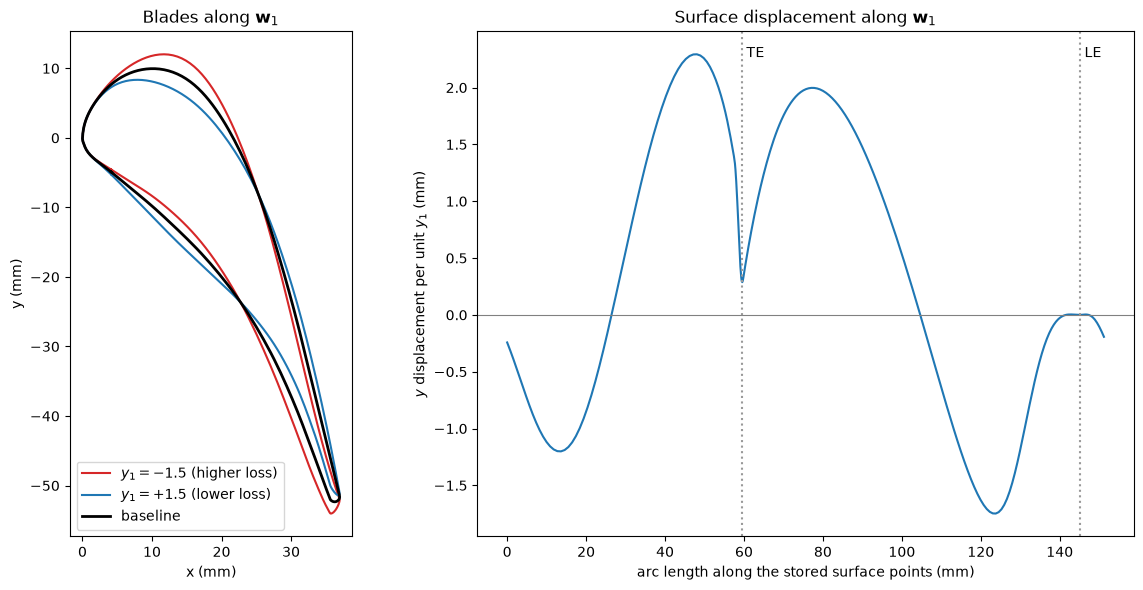

In [9]:
dw = Bmap.T @ w1                                  # surface displacement per unit active variable, m
t = 1.5
s_arc = np.r_[0, np.cumsum(np.hypot(np.diff(xb), np.diff(s0)))] * 1e3   # arc length along the stored points, mm
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={'width_ratios': [1, 1.4]})
for sgn, col, lab in [(-1, 'C3', '$y_1 = -1.5$ (higher loss)'), (1, 'C0', '$y_1 = +1.5$ (lower loss)')]:
    s = s0 + sgn * t * dw
    a1.plot(np.r_[xb, xb[0]] * 1e3, np.r_[s, s[0]] * 1e3, col, lw=1.5, label=lab)
a1.plot(np.r_[xb, xb[0]] * 1e3, np.r_[s0, s0[0]] * 1e3, 'k', lw=2, label='baseline')
a1.set_aspect('equal'); a1.set_xlabel('x (mm)'); a1.set_ylabel('y (mm)'); a1.legend(loc='lower left')
a1.set_title('Blades along $\\mathbf{w}_1$')
a2.plot(s_arc, dw * 1e3, 'C0')
a2.axhline(0, color='0.5', lw=0.8)
i_te, i_le = int(np.argmax(xb)), int(np.argmin(xb))
for i, name in [(i_te, 'TE'), (i_le, 'LE')]:
    a2.axvline(s_arc[i], color='0.6', ls=':')
    a2.annotate(name, (s_arc[i], 0.97), xycoords=('data', 'axes fraction'), ha='left', va='top',
                xytext=(3, 0), textcoords='offset points')
a2.set_xlabel('arc length along the stored surface points (mm)')
a2.set_ylabel('$y$ displacement per unit $y_1$ (mm)')
a2.set_title('Surface displacement along $\\mathbf{w}_1$')
fig.tight_layout()
plt.close(fig)
print(f'stored points: index 0 at x = {xb[0] * 1e3:.2f} mm, trailing edge (max x) at index {i_te}, '
      f'leading edge (min x) at index {i_le}')
print(f'displacement per unit y1: from {dw.min() * 1e3:+.2f} to {dw.max() * 1e3:+.2f} mm; '
      f'largest |.| at x = {xb[np.argmax(np.abs(dw))] * 1e3:.1f} mm')
fig

Moving along $+\mathbf w_1$ lowers the loss. The lower-loss blade ($y_1 = +1.5$, blue) has a lower, flatter forward suction surface (the convex upper curve) and a straighter pressure surface; the higher-loss blade (red) has a higher suction-side peak, a more concave pressure surface and a trailing edge moved down. The displacement per unit $y_1$ runs from −1.75 to +2.29 mm along the surface; it is largest at $x = 32.3$ mm, in the rear third of the blade, and close to zero around the leading edge. The paper does not draw this direction; its blade envelopes (Figs. 2 and 11) show the complementary, loss-invariant directions.

active variable y1 = w1^T x: range [-1.64, 2.20]; corr(y1, Yp) = -0.911
three largest Yp: 0.1055 at y1 = -1.32, 0.1041 at y1 = -1.48, 0.1010 at y1 = -1.64


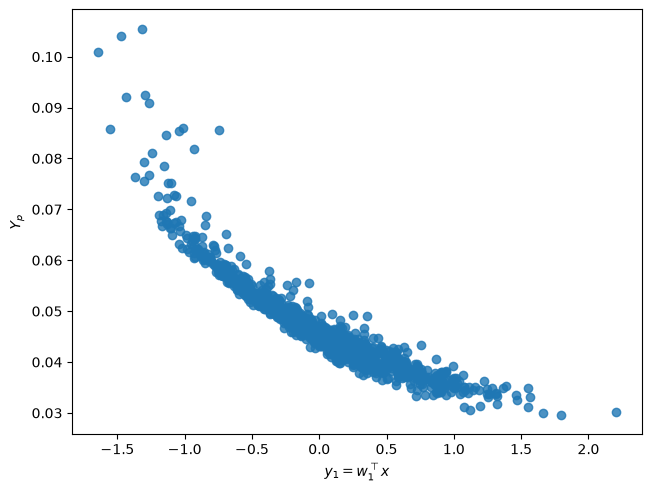

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=Xf, f=f, dims=1, qoi_label='$Y_p$')
plt.close(fig)
y1 = space.to_normalized(Xf) @ w1
top = np.argsort(f)[-3:]
print(f'active variable y1 = w1^T x: range [{y1.min():.2f}, {y1.max():.2f}]; corr(y1, Yp) = {np.corrcoef(y1, f)[0, 1]:.3f}')
print('three largest Yp:', ', '.join(f'{f[i]:.4f} at y1 = {y1[i]:.2f}' for i in top[::-1]))
fig

$Y_p$ falls along $y_1$ on a convex curve, from about 0.10 near $y_1 = -1.5$ to 0.03 near $y_1 = 2$, as in the paper's Fig. 9(b); $\mathrm{corr}(y_1, Y_p) = -0.911$, and $y_1$ ranges over $[-1.64, 2.20]$. The three highest losses, 0.1055, 0.1041 and 0.1010, lie at $y_1 = -1.32$, $-1.48$ and $-1.64$, where Fig. 9(b) has its three highest points (about 0.105, 0.104 and 0.101 at $u \approx -1.25$, $-1.45$ and $-1.7$, read from the figure). The scatter about the trend is largest at negative $y_1$, where the loss is high.

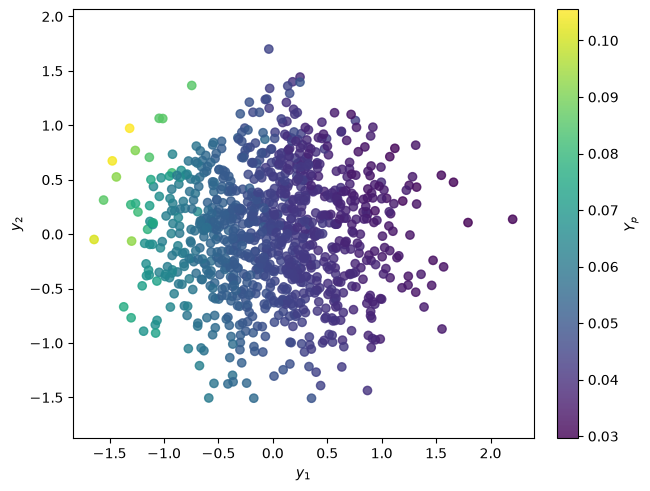

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=Xf, f=f, dims=2, qoi_label='$Y_p$')
plt.close(fig)
fig

With two active variables, the colour also changes along $y_2$ at negative $y_1$: near $y_1 = -1.3$ the highest losses have $y_2 > 0$. The 2-D surrogate below picks this up, but the eigenvalues and the bootstrap say that only the first direction is reliably estimated.

#### Cross-check: local linear gradients

A second estimator that makes no global assumption on the form of $Y_p$: at each run, a linear least-squares fit to its nearest neighbours (the library default, $p = \lfloor 1.7\,m\rfloor = 34$ points) gives a gradient, and the usual gradient-based matrix $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i\nabla f_i^T$ follows (`estimator="as"`). In 20 dimensions 34 neighbours out of 997 are not close, so these gradients are smoothed over a region, which damps curvature and the small eigenvalues.

local linear gradients and bootstrap: 2.4 s
eigenvalues: [2.52e-04 5.68e-06 4.60e-06 3.69e-06 3.27e-06 3.09e-06] ...
n = 1; lambda_1/lambda_2 = 44.3, lambda_2/lambda_3 = 1.24; eigenvalues 3-20 span 1.3e-06 to 4.6e-06
|w1(local linear) . w1(QPHD)| = 0.9957; subspace distance for k = 1: 0.093
bootstrap mean subspace distance, k = 1: 0.018


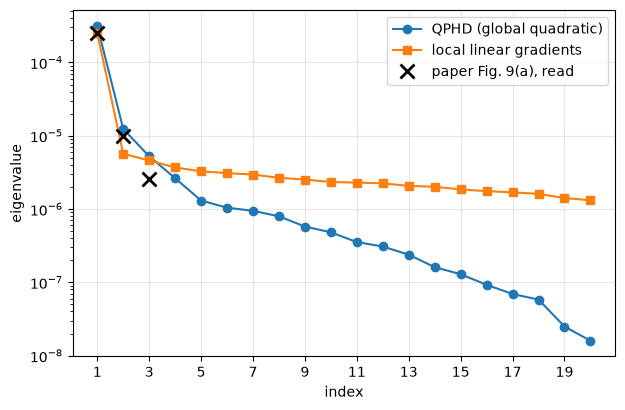

In [12]:
t0 = time.perf_counter()
gl = ac.local_linear_gradients(X=Xf, f=f, space=space)
sub_ll = ac.active_subspace(space=space, grads=gl, nboot=500, rng=SEED)
sub_ll = ac.orient(sub_ll, by='reference', reference=sub, columns=2)
lam_ll = sub_ll.eigenvalues
print(f'local linear gradients and bootstrap: {time.perf_counter() - t0:.1f} s')
print('eigenvalues:', np.array2string(lam_ll[:6], precision=2), '...')
print(f'n = {sub_ll.n}; lambda_1/lambda_2 = {lam_ll[0] / lam_ll[1]:.1f}, lambda_2/lambda_3 = {lam_ll[1] / lam_ll[2]:.2f}; '
      f'eigenvalues 3-20 span {lam_ll[19]:.1e} to {lam_ll[2]:.1e}')
print(f'|w1(local linear) . w1(QPHD)| = {abs(sub_ll.W[:, 0] @ w1):.4f}; '
      f'subspace distance for k = 1: {np.linalg.norm(sub_ll.W[:, :1].T @ sub.W[:, 1:], 2):.3f}')
print(f'bootstrap mean subspace distance, k = 1: {sub_ll.bootstrap_distances.mean(axis=0)[0]:.3f}')
fig, ax = plt.subplots(figsize=(7, 4.5))
k = np.arange(1, 21)
ax.semilogy(k, lam, 'o-', label='QPHD (global quadratic)')
ax.semilogy(k, lam_ll, 's-', label='local linear gradients')
ax.semilogy([1, 2, 3], paper_lam, 'kx', markersize=10, mew=2, label='paper Fig. 9(a), read')
ax.set_xlabel('index'); ax.set_ylabel('eigenvalue'); ax.set_xticks(k[::2]); ax.grid(True, alpha=0.3)
ax.legend()
plt.close(fig)
fig

Local linear gradients give the same first direction, $|\mathbf w_1^{\mathrm{LL}}\cdot\mathbf w_1^{\mathrm{QPHD}}| = 0.9957$ (subspace distance 0.093), and also $n = 1$. Their $\lambda_1 = 2.52\times10^{-4}$ is closer to the value read from Fig. 9(a), and their gap is larger, $\lambda_1/\lambda_2 = 44.3$, because the regional linear fits smooth away the curvature that feeds the QPHD $\lambda_2$ ($5.68\times10^{-6}$ against $1.24\times10^{-5}$). Their eigenvalues 3–20 sit on a plateau between $1.3\times10^{-6}$ and $4.6\times10^{-6}$, the floor set by the scatter of $Y_p$ about each local plane. The two estimators agree on what the data determine, the first direction and $n = 1$, and differ on the small eigenvalues, which neither determines.

#### Do $x_{10}$ and $x_{20}$ matter?

The stored surfaces do not move with $x_{10}$ or $x_{20}$. If the CFD surfaces did not move either, $Y_p$ cannot depend on them, and their weights in $\mathbf w_1$ measure estimation noise. A direct test with values only: the leave-one-out $R^2$ of the 20-input least-squares quadratic, with and without those two inputs.

In [13]:
keep = [j for j in range(20) if j not in (9, 19)]
q20 = ac.fit_surrogate(X=Xf, f=f, space=space, subspace=None, kind='poly', degree=2)
q18 = ac.fit_surrogate(X=Xf[:, keep], f=f, space=ac.Uniform(cd.LOWER[keep], cd.UPPER[keep]),
                       subspace=None, kind='poly', degree=2)
print(f'LOO R^2 of the full quadratic: 20 inputs {q20.loo_r_squared:.4f} (231 terms), '
      f'without x10 and x20 {q18.loo_r_squared:.4f} (190 terms)')
print(f'w1: x10 {w1[9]:+.3f}, x20 {w1[19]:+.3f} (QPHD); {sub_ll.W[9, 0]:+.3f}, {sub_ll.W[19, 0]:+.3f} (local linear)')

LOO R^2 of the full quadratic: 20 inputs 0.9208 (231 terms), without x10 and x20 0.9251 (190 terms)
w1: x10 +0.012, x20 -0.013 (QPHD); +0.015, -0.008 (local linear)


Dropping $x_{10}$ and $x_{20}$ raises the leave-one-out $R^2$ of the quadratic slightly, from 0.9208 to 0.9251. The data show no dependence of $Y_p$ on them, and their weights in $\mathbf w_1$ (+0.012 and −0.013 for QPHD, +0.015 and −0.008 for local linear) are within the bootstrap band around 0. They act as two dummy inputs, a built-in check on the estimators. Whether the SU2 meshes moved with them is a question for the authors (`DATA.md`).

#### Surrogates

We fit polynomials in the active variables and report the leave-one-out $R^2$, to compare with the 20-input quadratic above and the paper's sparse cubic (test $R^2 = 0.957$ on 200 held-out runs, Fig. 8(b), p. 13).

1-D cubic      in the active variables: LOO R^2 = 0.9243
1-D quartic    in the active variables: LOO R^2 = 0.9271
2-D quadratic  in the active variables: LOO R^2 = 0.9309
2-D cubic      in the active variables: LOO R^2 = 0.9568
20-D quadratic in all inputs:          LOO R^2 = 0.9208


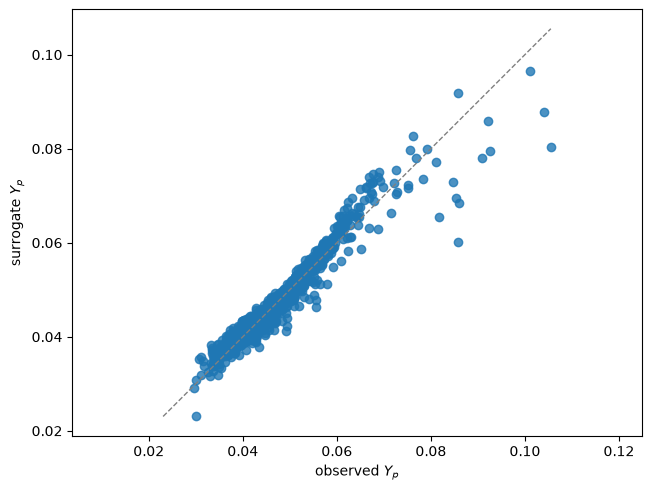

In [14]:
sub2 = ac.with_dimension(sub, 2)
sur = {}
for name, s, deg in [('1-D cubic', sub, 3), ('1-D quartic', sub, 4), ('2-D quadratic', sub2, 2), ('2-D cubic', sub2, 3)]:
    sur[name] = ac.fit_surrogate(X=Xf, f=f, subspace=s, kind='poly', degree=deg)
    print(f'{name:14s} in the active variables: LOO R^2 = {sur[name].loo_r_squared:.4f}')
print(f'{"20-D quadratic":14s} in all inputs:          LOO R^2 = {q20.loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur['1-D cubic'], X=Xf, f=f, qoi_label='$Y_p$')
plt.close(fig)
fig

A cubic in the single active variable has leave-one-out $R^2 = 0.9243$, more than the 20-input quadratic with 231 coefficients (0.9208). A cubic in two active variables reaches 0.9568, the same as the paper's test $R^2 = 0.957$ for its 1771-term sparse cubic; the paper's number is a test $R^2$ on 200 held-out runs, not a leave-one-out $R^2$, so the comparison is indicative. The fit plot shows that the 1-D cubic's largest errors are at the high-loss end.

### Comparison with the paper

The cell computes the notebook's values; the paper's eigenvalues and active-coordinate range are read from Fig. 9 and are approximate.

In [15]:
s_f = f.std(ddof=1)
rows = [
    ('CFD runs used', '1000 (800 train / 200 test)', f'{ok.sum()} of {len(f_all)} (3 inf dropped)'),
    ('lambda_1 (Fig. 9(a))', '~2.5e-4', f'{lam[0]:.2e} QPHD, {lam_ll[0]:.2e} local linear'),
    ('lambda_2 (Fig. 9(a))', '~1.0e-5', f'{lam[1]:.2e} QPHD, {lam_ll[1]:.2e} local linear'),
    ('lambda_3 (Fig. 9(a))', '~2.6e-6', f'{lam[2]:.2e} QPHD, {lam_ll[2]:.2e} local linear'),
    ('lambda_1/lambda_2', '~25', f'{lam[0] / lam[1]:.1f} QPHD, {lam_ll[0] / lam_ll[1]:.1f} local linear'),
    ('active dimension', '1', f'{sub.n} (gap rule)'),
    ('active coordinate range (Fig. 9(b))', '~[-1.7, 1.7]', f'[{y1.min():.2f}, {y1.max():.2f}]'),
    ('Yp range (Fig. 9(b))', '~0.03 to 0.105', f'{f.min():.4f} to {f.max():.4f}'),
    ('polynomial R^2', '0.957 (sparse cubic, test)', f'{q20.loo_r_squared:.3f} (20-D quadratic, LOO); '
                                                      f'{sur["2-D cubic"].loo_r_squared:.3f} (2-D cubic, LOO)'),
    ('2-sd interval of Yp, random designs (p. 13)', '0.0185', f'2s = {2 * s_f:.4f}, 4s = {4 * s_f:.4f}'),
    ('2-sd interval of Yp, invariant designs (p. 13)', '0.0011', 'not in the data'),
]
for q, p, v in rows:
    print(f'{q:46s} {p:>28s}   {v}')

CFD runs used                                   1000 (800 train / 200 test)   997 of 1000 (3 inf dropped)
lambda_1 (Fig. 9(a))                                                ~2.5e-4   3.17e-04 QPHD, 2.52e-04 local linear
lambda_2 (Fig. 9(a))                                                ~1.0e-5   1.24e-05 QPHD, 5.68e-06 local linear
lambda_3 (Fig. 9(a))                                                ~2.6e-6   5.24e-06 QPHD, 4.60e-06 local linear
lambda_1/lambda_2                                                       ~25   25.6 QPHD, 44.3 local linear
active dimension                                                          1   1 (gap rule)
active coordinate range (Fig. 9(b))                            ~[-1.7, 1.7]   [-1.64, 2.20]
Yp range (Fig. 9(b))                                         ~0.03 to 0.105   0.0297 to 0.1055
polynomial R^2                                   0.957 (sparse cubic, test)   0.921 (20-D quadratic, LOO); 0.957 (2-D cubic, LOO)
2-sd interval of Yp, random design

| Quantity | Paper value | Notebook value |
|---|---|---|
| CFD runs | 1000 (800 training, 200 test; p. 12) | 997 of 1000 (3 with `inf` loss dropped) |
| Gradient model | sparse total-order cubic, 1771 terms, compressed sensing (p. 12) | least-squares quadratic, 231 terms (QPHD); local linear |
| $\lambda_1$ | about $2.5\times10^{-4}$ (Fig. 9(a), read) | $3.17\times10^{-4}$ (QPHD), $2.52\times10^{-4}$ (local linear) |
| $\lambda_2$ | about $1.0\times10^{-5}$ (Fig. 9(a), read) | $1.24\times10^{-5}$ (QPHD), $5.68\times10^{-6}$ (local linear) |
| $\lambda_3$ | about $2.6\times10^{-6}$ (Fig. 9(a), read) | $5.24\times10^{-6}$ (QPHD), $4.60\times10^{-6}$ (local linear) |
| $\lambda_1/\lambda_2$ | about 25 | 25.6 (QPHD), 44.3 (local linear) |
| Active dimension | 1 (p. 13) | 1 (eigenvalue-gap rule, both estimators) |
| First eigenvector | not reported | dominated by $x_{11}$–$x_{14}$ and $x_5$–$x_7$ (0.938 of $\lVert\mathbf w_1\rVert^2$) |
| Active coordinate range | about $[-1.7, 1.7]$ (Fig. 9(b), read) | $[-1.64, 2.20]$ |
| $Y_p$ range | about 0.03 to 0.105 (Fig. 9(b), read) | 0.0297 to 0.1055 |
| Polynomial $R^2$ | 0.957 (sparse cubic, test set; Fig. 8(b)) | 0.921 (20-D quadratic, LOO); 0.957 (2-D cubic in $y_1, y_2$, LOO) |
| Two-standard-deviation interval of $Y_p$, random designs | 0.0185 (p. 13) | $2s = 0.0194$, $4s = 0.0388$ |
| Same, 500 loss-invariant designs | 0.0011 (p. 13) | not in the data |

The notebook reproduces the paper's main finding from its published runs: a one-dimensional active subspace for $Y_p$, with a gap of about 25 between the first two eigenvalues and the sufficient summary plot of Fig. 9(b), down to the positions of the three highest losses. The eigenvalues agree to the precision of reading a log-scale figure for $\lambda_2$, and to about 25 % for $\lambda_1$ (QPHD) or better (local linear); the two estimators and the paper use different gradient models, and the small eigenvalues depend on the model. The paper does not define its "length of the two-standard-deviation interval"; 0.0185 is closest to twice the sample standard deviation of the 997 finite runs (0.0194), with the remaining difference possibly from a different subset of runs. The paper says Fig. 9(b) plots "all 1000 geometries", but three runs have no finite loss in the published file, so at most 997 can appear. The loss values of the 500 loss-invariant designs that the paper ran (Fig. 10) are not in the published file, so the inactive-subspace check of Sec. 4.2 cannot be repeated here.

### References

[1] C. Y. Wong, P. Seshadri, A. Scillitoe, A. B. Duncan, and G. Parks. [Blade envelopes part I: concept and methodology](https://doi.org/10.1115/1.4053239). *Journal of Turbomachinery*, 144(6), 2022. Preprint arXiv:2011.11636. Data: [equadratures/data-sets](https://github.com/equadratures/data-sets), `blade_envelopes`. Run scripts: [ncywong/VKI_CFD](https://github.com/ncywong/VKI_CFD).

[2] T. Arts and M. Lambert de Rouvroit. [Aero-thermal performance of a two-dimensional highly loaded transonic turbine nozzle guide vane: a test case for inviscid and viscous flow computations](https://doi.org/10.1115/1.2927978). *Journal of Turbomachinery*, 114(1):147–154, 1992.

[3] T. D. Economon, F. Palacios, S. R. Copeland, T. W. Lukaczyk, and J. J. Alonso. [SU2: an open-source suite for multiphysics simulation and design](https://doi.org/10.2514/1.J053813). *AIAA Journal*, 54(3):828–846, 2016.

[4] P. Seshadri, S. Shahpar, P. Constantine, G. Parks, and M. Adams. [Turbomachinery active subspace performance maps](https://doi.org/10.1115/1.4038839). *Journal of Turbomachinery*, 140(4):041003, 2018.

[5] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[6] K.-C. Li. [On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma](https://doi.org/10.1080/01621459.1992.10476258). *Journal of the American Statistical Association*, 87(420):1025–1039, 1992.

[R1]: https://doi.org/10.1115/1.4053239
[R2]: https://doi.org/10.1115/1.2927978
[R3]: https://doi.org/10.2514/1.J053813

### Acknowledgments

From [[1]][R1] (preprint, p. 17): "The first author acknowledges financial support from the Cambridge Trust, Jesus College, Cambridge, and the Data-Centric Engineering programme of The Alan Turing Institute. The second author was funded through a Rolls-Royce research fellowship and the third author was funded through the Digital Twins in Aeronautics grant as part of the Strategic Priorities Fund EP/T001569/1. The fourth author was supported by the Lloyd's Register Foundation Programme on Data Centric Engineering and by The Alan Turing Institute under the EPSRC grant EP/N510129/1."

In [16]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 22.1 s
